Names: ______________________  |  Section: ______  |  Roll Nos.: ______

## FairValue: Used Car Price Prediction & Depreciation Analyzer (CarDekho)
**Dataset:** CarDekho Used Car Data (`cardekho_dataset.csv`), Kaggle: `manishkr1754/cardekho-used-car-data`

**Aim:** Analyse used-car listings in India and build regression models (Ridge, Random Forest, HistGradientBoosting) that predict `selling_price`, then study how price changes with vehicle age and distance driven.

**Target:** `selling_price` (Indian Rupees, ₹). This is **not** a time-series problem, so rows are split randomly (80:20).
Every number below is computed from the file when you run the notebook.

##### 1. Importing Libraries

In [24]:
!pip install -q kagglehub

In [25]:
import os, glob, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

##### 2. Loading the Dataset
Downloads from Kaggle with `kagglehub`; if that fails (no internet / no login), place `cardekho_dataset.csv` next to this notebook.

In [26]:
try:
    import kagglehub
    path = kagglehub.dataset_download("manishkr1754/cardekho-used-car-data")
    csv_file = glob.glob(path + "/**/cardekho_dataset.csv", recursive=True)[0]
except Exception as e:
    print("Kaggle download not used:", e)
    csv_file = "cardekho_dataset.csv"

assert os.path.exists(csv_file), "cardekho_dataset.csv not found. Download it from Kaggle and keep it next to this notebook."
file_mb = os.path.getsize(csv_file) / 1e6
print(f"File: {csv_file} | {file_mb:.2f} MB")
raw_df = pd.read_csv(csv_file)
raw_df = raw_df.drop(columns=[c for c in raw_df.columns if c.startswith("Unnamed")])
raw_df.head()

File: C:\Users\user\.cache\kagglehub\datasets\manishkr1754\cardekho-used-car-data\versions\2\cardekho_dataset.csv | 1.36 MB


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


##### 3. Understanding the Data

In [27]:
print("Shape:", raw_df.shape)
raw_df.info()

Shape: (15411, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  int64  
 4   km_driven          15411 non-null  int64  
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  int64  
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  int64  
 12  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.5+ MB


In [28]:
raw_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_name,15411,121,Hyundai i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,15411,32,Maruti,4992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,15411,120,i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_age,15411.0,NaN,NaN,NaN,6.036338,3.013291,0.0,4.0,6.0,8.0,29.0
km_driven,15411.0,NaN,NaN,NaN,55616.480631,51618.548422,100.0,30000.0,50000.0,70000.0,3800000.0
seller_type,15411,3,Dealer,9539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,15411,5,Petrol,7643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission_type,15411,2,Manual,12225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,15411.0,NaN,NaN,NaN,19.701151,4.171265,4.0,17.0,19.67,22.7,33.54
engine,15411.0,NaN,NaN,NaN,1486.057751,521.106696,793.0,1197.0,1248.0,1582.0,6592.0


In [29]:
print("Missing values:\n", raw_df.isnull().sum())
print("\nDuplicate rows:", raw_df.duplicated().sum())

Missing values:
 car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Duplicate rows: 167


##### 4. Data Cleaning & Feature Engineering
* Remove duplicates and rows with missing/invalid values.
* Remove extreme price outliers (outside the 0.5–99.5 percentile) and impossible values.
* `km_per_year = km_driven / max(vehicle_age, 1)`.
* Remaining gaps (if any) are imputed **inside the pipeline**, fitted on training data only, so there is no leakage.
* `car_name` is dropped because it just repeats `brand + model`.

In [30]:
REQUIRED = ["vehicle_age", "km_driven", "brand", "model", "selling_price"]
assert all(c in raw_df.columns for c in REQUIRED), f"Missing columns. Found: {list(raw_df.columns)}"

df = raw_df.drop(columns=["car_name"], errors="ignore").drop_duplicates().dropna(subset=REQUIRED).copy()
n_dups = len(raw_df) - len(df)
df = df[(df["selling_price"] > 0) & df["vehicle_age"].between(0, 30) & df["km_driven"].between(0, 600_000)]
for c in ["engine", "max_power", "mileage"]:
    if c in df: df = df[(df[c] > 0) | df[c].isna()]
lo, hi = df["selling_price"].quantile([0.005, 0.995])
df = df[df["selling_price"].between(lo, hi)].reset_index(drop=True)
df["km_per_year"] = df["km_driven"] / df["vehicle_age"].clip(lower=1)

NUM = [c for c in ["vehicle_age", "km_driven", "km_per_year", "mileage", "engine", "max_power", "seats"] if c in df]
CAT = [c for c in ["brand", "model", "seller_type", "fuel_type", "transmission_type"] if c in df]
FEATURES = NUM + CAT
print(f"Rows: {len(raw_df):,} raw -> {len(df):,} cleaned | duplicates removed: {n_dups} | price kept: ₹{lo:,.0f} – ₹{hi:,.0f}")
print("Numeric:", NUM, "\nCategorical:", CAT)

Rows: 15,411 raw -> 15,084 cleaned | duplicates removed: 167 | price kept: ₹100,000 – ₹5,748,810
Numeric: ['vehicle_age', 'km_driven', 'km_per_year', 'mileage', 'engine', 'max_power', 'seats'] 
Categorical: ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


##### 5. Descriptive Statistics of the Target

In [31]:
x = df["selling_price"]
print("Mean:", round(x.mean()), "| Median:", round(x.median()), "| Std:", round(x.std()), "| Skew:", round(x.skew(), 2))
print("Min:", x.min(), "| Max:", x.max(), "| IQR:", round(x.quantile(.75) - x.quantile(.25)))

Mean: 741703 | Median: 556500 | Std: 669310 | Skew: 3.38
Min: 100000 | Max: 5743000 | IQR: 427500


##### 6. Exploratory Data Analysis
6.1 Price distribution and missing values

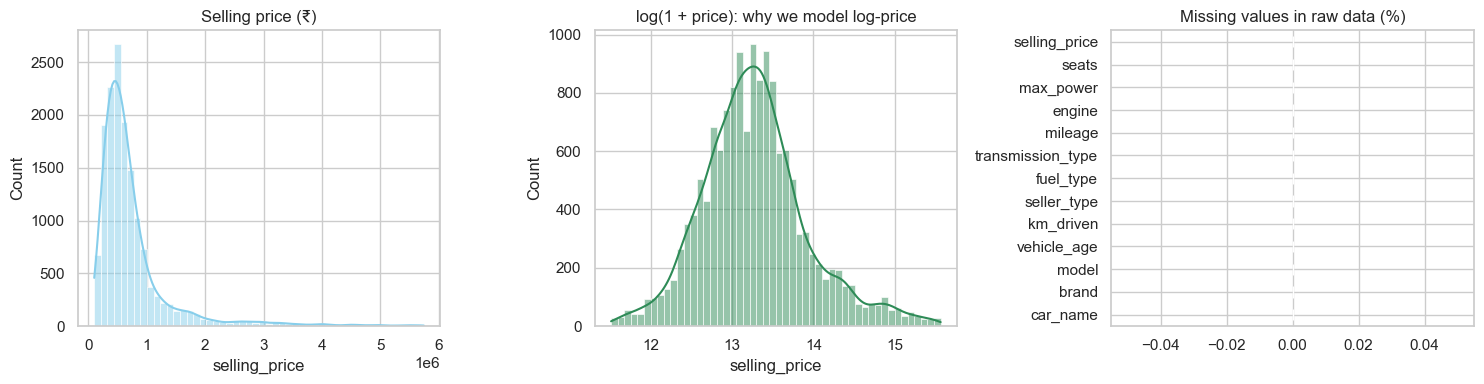

In [32]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); sns.histplot(df["selling_price"], bins=50, kde=True, color="skyblue"); plt.title("Selling price (₹)")
plt.subplot(1, 3, 2); sns.histplot(np.log1p(df["selling_price"]), bins=50, kde=True, color="seagreen"); plt.title("log(1 + price): why we model log-price")
plt.subplot(1, 3, 3); (raw_df.isna().mean() * 100).sort_values().plot.barh(color="indianred"); plt.title("Missing values in raw data (%)")
plt.tight_layout(); plt.show()

6.2 Brand comparison

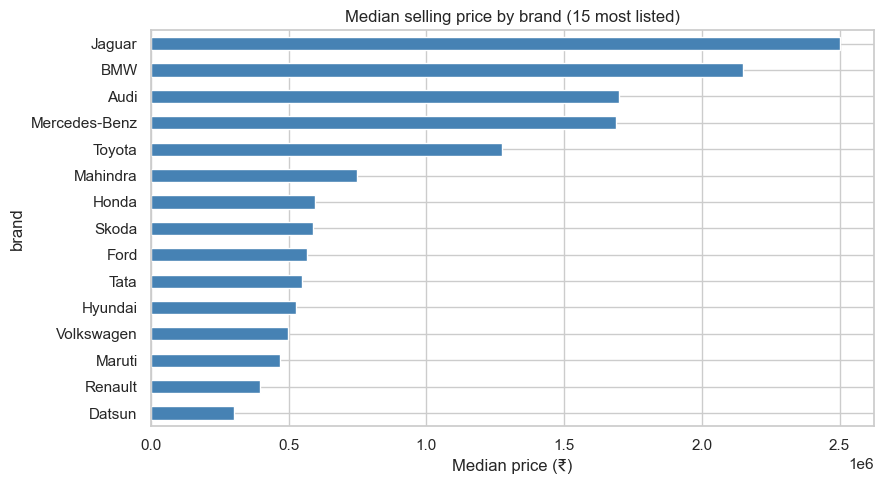

In [33]:
top = df["brand"].value_counts().head(15).index
g = df[df["brand"].isin(top)].groupby("brand")["selling_price"].median().sort_values()
plt.figure(figsize=(9, 5))
g.plot(kind="barh", color="steelblue")
plt.title("Median selling price by brand (15 most listed)"); plt.xlabel("Median price (₹)")
plt.tight_layout(); plt.show()

6.3 Vehicle age vs price and distance driven vs price

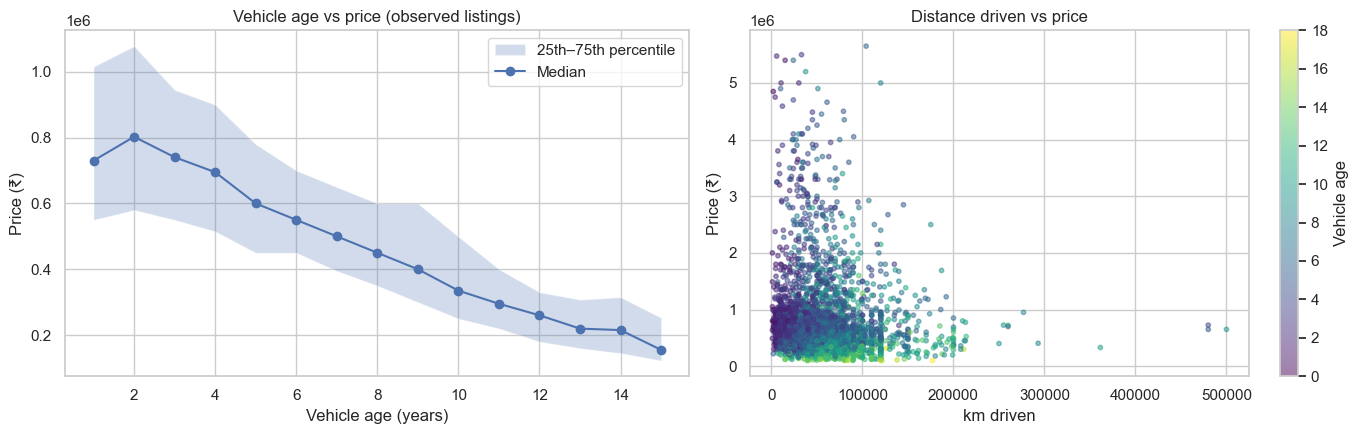

In [34]:
age_t = df.groupby("vehicle_age")["selling_price"].agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n="count").reset_index()
age_t = age_t[age_t["n"] >= 15]

plt.figure(figsize=(14, 4.5))
plt.subplot(1, 2, 1)
plt.fill_between(age_t["vehicle_age"], age_t["q25"], age_t["q75"], alpha=0.25, label="25th–75th percentile")
plt.plot(age_t["vehicle_age"], age_t["median"], marker="o", label="Median")
plt.title("Vehicle age vs price (observed listings)"); plt.xlabel("Vehicle age (years)"); plt.ylabel("Price (₹)"); plt.legend()
plt.subplot(1, 2, 2)
smp = df.sample(min(4000, len(df)), random_state=1)
sc = plt.scatter(smp["km_driven"], smp["selling_price"], c=smp["vehicle_age"], cmap="viridis", alpha=0.5, s=10)
plt.colorbar(sc, label="Vehicle age"); plt.title("Distance driven vs price"); plt.xlabel("km driven"); plt.ylabel("Price (₹)")
plt.tight_layout(); plt.show()

6.4 Price by fuel, transmission, seller type and seats

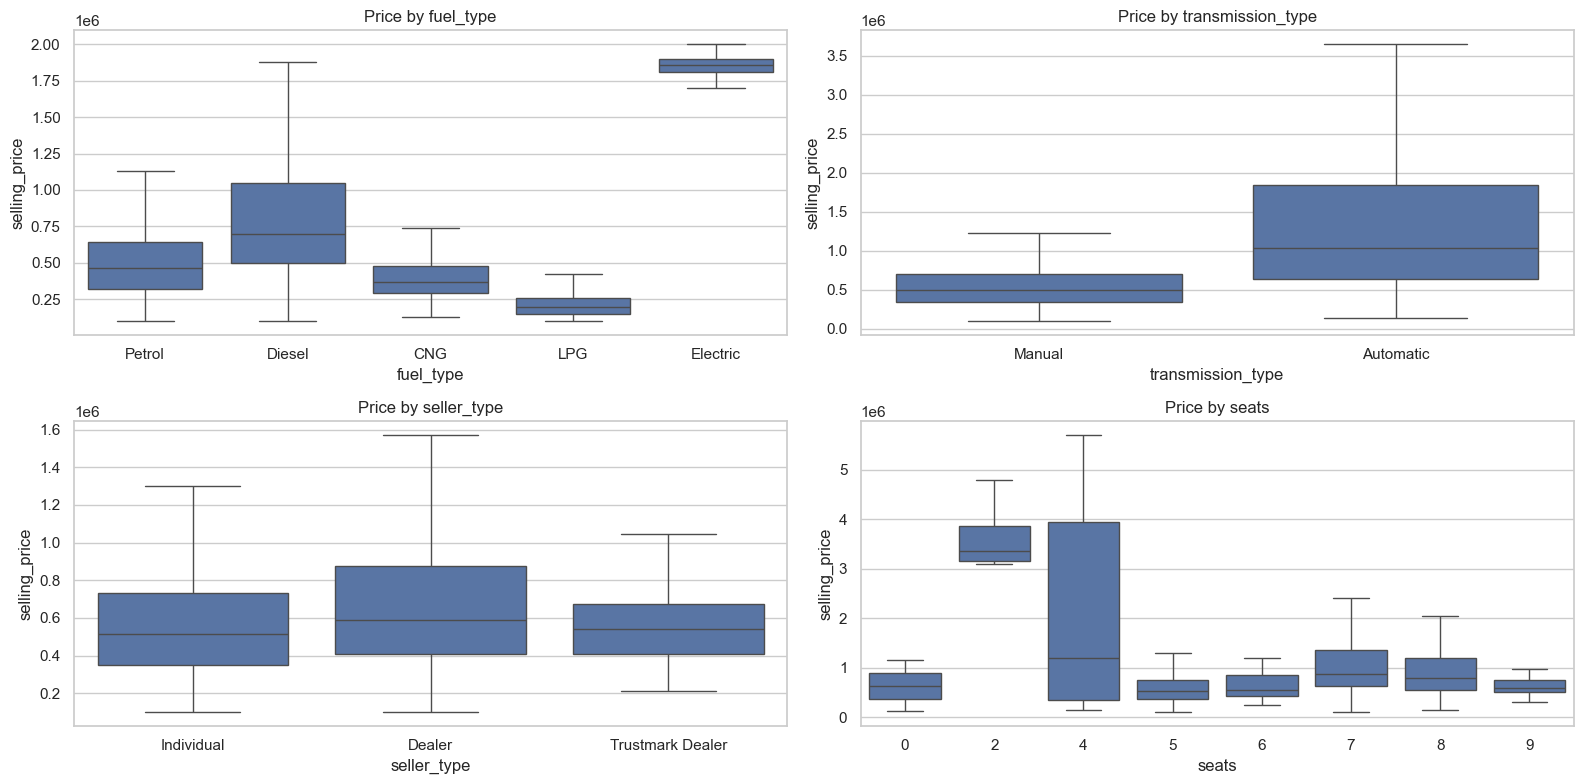

In [35]:
plt.figure(figsize=(16, 8))
for i, col in enumerate([c for c in ["fuel_type", "transmission_type", "seller_type", "seats"] if c in df]):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(data=df, x=col, y="selling_price", showfliers=False); plt.title("Price by " + col)
plt.tight_layout(); plt.show()

6.5 Correlation heatmap

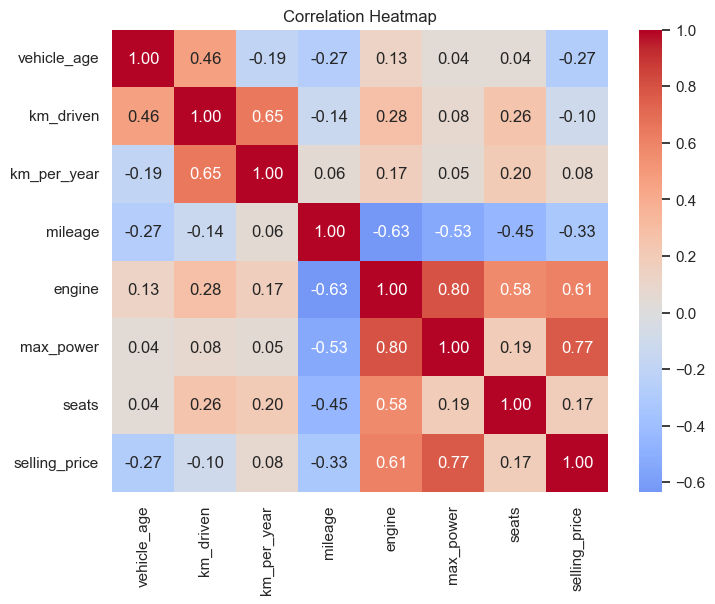

In [36]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUM + ["selling_price"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.show()

##### 7. Train-Test Split (80:20, random)

In [37]:
X, y = df[FEATURES], df["selling_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 12067 | Testing rows: 3017


##### 8. Preprocessing Pipelines
* **Linear (Ridge):** median-impute + scale numbers; one-hot encode categories (unseen values are ignored).
* **Tree models:** median-impute numbers; ordinal-encode categories (unseen values become -1).
* Target is modelled as `log1p(price)` using `TransformedTargetRegressor`, so predictions come back in ₹.

In [38]:
cat_imp = SimpleImputer(strategy="constant", fill_value="unknown")
pre_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", cat_imp), ("enc", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
pre_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", Pipeline([("imp", cat_imp), ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), CAT)])

def wrap(pre, model):
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("model", model)]), func=np.log1p, inverse_func=np.expm1)

##### 9. Training the Models (each model in its own cell, tuned with RandomizedSearchCV, 3-fold CV)
9.1 Ridge Regression

In [39]:
ridge_search = RandomizedSearchCV(
    wrap(pre_linear, Ridge()), {"regressor__model__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]},
    n_iter=6, cv=3, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Best params:", ridge_search.best_params_)
print("CV MAE: ₹", round(-ridge_search.best_score_))

Best params: {'regressor__model__alpha': 0.1}
CV MAE: ₹ 102534


9.2 Random Forest Regressor

In [40]:
rf_search = RandomizedSearchCV(
    wrap(pre_tree, RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    {"regressor__model__n_estimators": [100, 200], "regressor__model__max_depth": [12, 18, 25],
     "regressor__model__min_samples_leaf": [1, 2, 5], "regressor__model__max_features": [0.5, 0.8, 1.0]},
    n_iter=6, cv=3, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
print("CV MAE: ₹", round(-rf_search.best_score_))

Best params: {'regressor__model__n_estimators': 200, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_features': 0.5, 'regressor__model__max_depth': 18}
CV MAE: ₹ 94478


9.3 HistGradientBoosting Regressor

In [41]:
hgb_search = RandomizedSearchCV(
    wrap(pre_tree, HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    {"regressor__model__learning_rate": [0.03, 0.05, 0.1, 0.2], "regressor__model__max_iter": [200, 400, 600],
     "regressor__model__max_leaf_nodes": [15, 31, 63], "regressor__model__min_samples_leaf": [10, 20, 40],
     "regressor__model__l2_regularization": [0, 0.5, 1]},
    n_iter=8, cv=3, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
hgb_search.fit(X_train, y_train)
print("Best params:", hgb_search.best_params_)
print("CV MAE: ₹", round(-hgb_search.best_score_))

Best params: {'regressor__model__min_samples_leaf': 10, 'regressor__model__max_leaf_nodes': 63, 'regressor__model__max_iter': 600, 'regressor__model__learning_rate': 0.03, 'regressor__model__l2_regularization': 0.5}
CV MAE: ₹ 91710


##### 10. Model Evaluation (held-out 20% test set, in ₹)

In [42]:
def evaluate(name, search):
    p = search.best_estimator_.predict(X_test)
    return {"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": mean_squared_error(y_test, p) ** 0.5,
            "R2": r2_score(y_test, p), "CV MAE": -search.best_score_}

results = pd.DataFrame([evaluate("Ridge", ridge_search), evaluate("Random Forest", rf_search), evaluate("HistGradientBoosting", hgb_search)])
results = results.sort_values("MAE").reset_index(drop=True)
results.round(3)

,Model,MAE,RMSE,R2,CV MAE
0,Random Forest,89660.680,176751.628,0.927,94478.465
1,HistGradientBoosting,91297.930,179563.670,0.925,91709.863
2,Ridge,102967.669,215536.067,0.892,102533.575


Best model (lowest test MAE): Random Forest


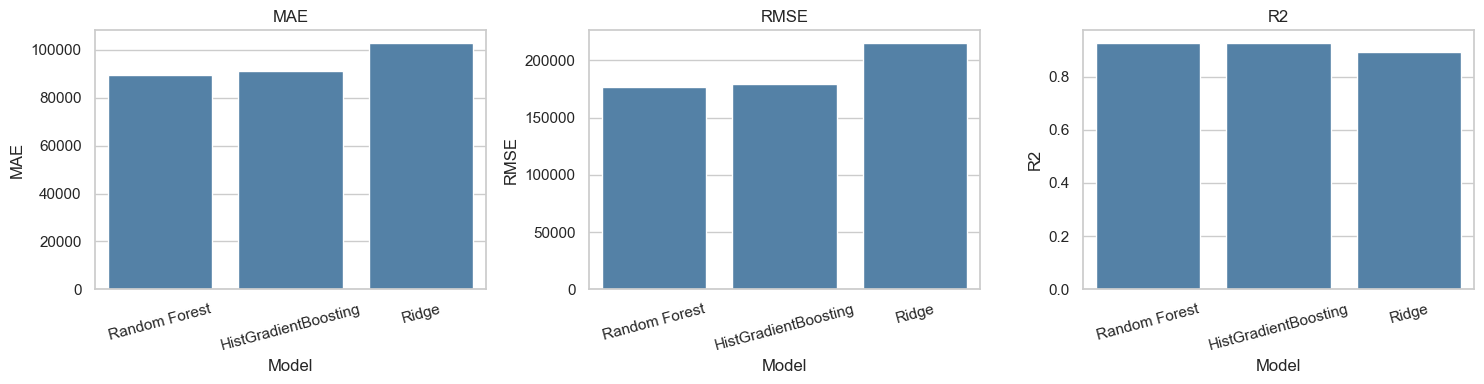

In [43]:
fitted = {"Ridge": ridge_search.best_estimator_, "Random Forest": rf_search.best_estimator_, "HistGradientBoosting": hgb_search.best_estimator_}
BEST = results.loc[0, "Model"]
best_pipe = fitted[BEST]
best_pred = best_pipe.predict(X_test)
print("Best model (lowest test MAE):", BEST)

plt.figure(figsize=(15, 4))
for i, m in enumerate(["MAE", "RMSE", "R2"]):
    plt.subplot(1, 3, i + 1); sns.barplot(data=results, x="Model", y=m, color="steelblue"); plt.title(m); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

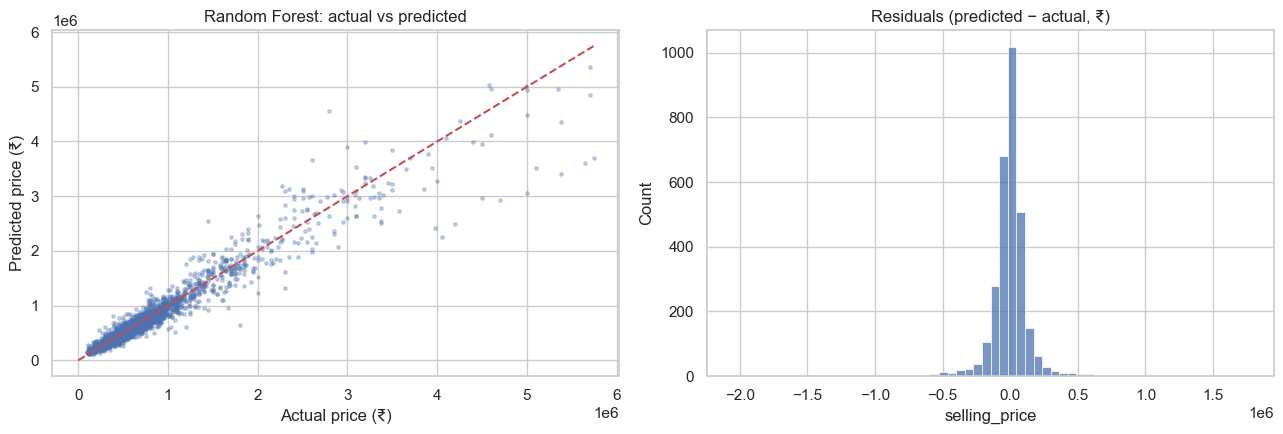

In [44]:
plt.figure(figsize=(13, 4.5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, best_pred, s=6, alpha=.3); plt.plot([0, y_test.max()], [0, y_test.max()], "r--")
plt.xlabel("Actual price (₹)"); plt.ylabel("Predicted price (₹)"); plt.title(BEST + ": actual vs predicted")
plt.subplot(1, 2, 2); sns.histplot(best_pred - y_test, bins=60); plt.title("Residuals (predicted − actual, ₹)")
plt.tight_layout(); plt.show()

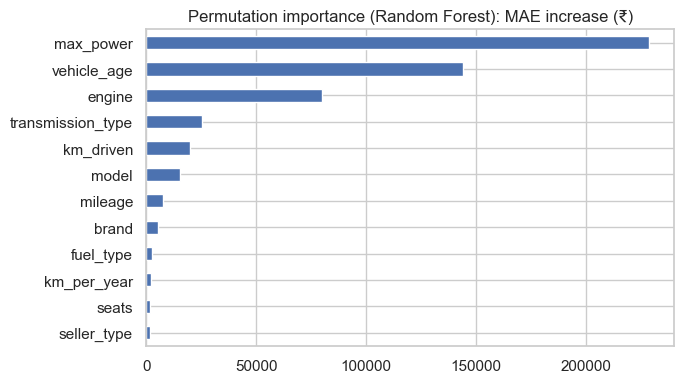

In [45]:
pi_X = X_test.sample(min(2000, len(X_test)), random_state=1)
pi = permutation_importance(best_pipe, pi_X, y_test.loc[pi_X.index], n_repeats=3, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(7, 4)); imp.plot.barh(title=f"Permutation importance ({BEST}): MAE increase (₹)"); plt.tight_layout(); plt.show()

##### 11. Predicting on New Input (with validation)

In [46]:
def predict_price(pipe, vehicle_age, km_driven, brand, model, **extra):
    """Validate input, build the same features as training, return predicted price in ₹."""
    if not 0 <= float(vehicle_age) <= 30: raise ValueError("vehicle_age must be between 0 and 30 years")
    if not 0 <= float(km_driven) <= 600_000: raise ValueError("km_driven must be between 0 and 600,000")
    row = {"vehicle_age": float(vehicle_age), "km_driven": float(km_driven), "brand": str(brand).strip(), "model": str(model).strip()}
    row.update({k: (np.nan if v in (None, "", "unknown") else v) for k, v in extra.items()})
    d = pd.DataFrame([row])
    d["km_per_year"] = d["km_driven"] / d["vehicle_age"].clip(lower=1)
    for c in FEATURES:
        if c not in d: d[c] = np.nan            # missing optional fields -> imputed by the pipeline
    return float(pipe.predict(d[FEATURES])[0])

mb = df["brand"].mode()[0]; mm = df.loc[df["brand"] == mb, "model"].mode()[0]
print(f"{mb} {mm}, 5 yrs, 50,000 km: ₹{predict_price(best_pipe, 5, 50000, mb, mm, fuel_type='Petrol', transmission_type='Manual'):,.0f}")
print(f"Unseen brand/model (no crash): ₹{predict_price(best_pipe, 3, 30000, 'NewBrand', 'X1', fuel_type='Hydrogen'):,.0f}")
try: predict_price(best_pipe, -2, 1e7, mb, mm)
except ValueError as e: print("Validation works:", e)

Maruti Swift Dzire, 5 yrs, 50,000 km: ₹671,903
Unseen brand/model (no crash): ₹946,380
Validation works: vehicle_age must be between 0 and 30 years


In [47]:
s = X_test.sample(8, random_state=3).assign(actual=y_test, predicted=lambda d: best_pipe.predict(d[FEATURES]).round(0))
s[["brand", "model", "vehicle_age", "km_driven", "actual", "predicted"]]

,brand,model,vehicle_age,km_driven,actual,predicted
1566,Maruti,Wagon R,7,25978,325000,352188.0
9197,Honda,City,9,75000,400000,442106.0
3325,Hyundai,i20,9,79330,375000,376755.0
6248,Mahindra,XUV500,7,145000,750000,780065.0
4125,Hyundai,i10,12,80000,145000,164321.0
8480,Hyundai,Grand,2,8000,635000,582142.0
8198,Skoda,Rapid,7,87232,260000,504717.0
921,Hyundai,Aura,1,4500,900000,633683.0


##### 12. Depreciation Analysis
* **Observed (historical, cross-sectional):** median price of *different* cars at each age. It is not one car tracked over time.
* **Simulated (model estimate):** one reference car where only age changes. Two scenarios: distance driven grows with age, or distance is held fixed (isolates pure age effect).

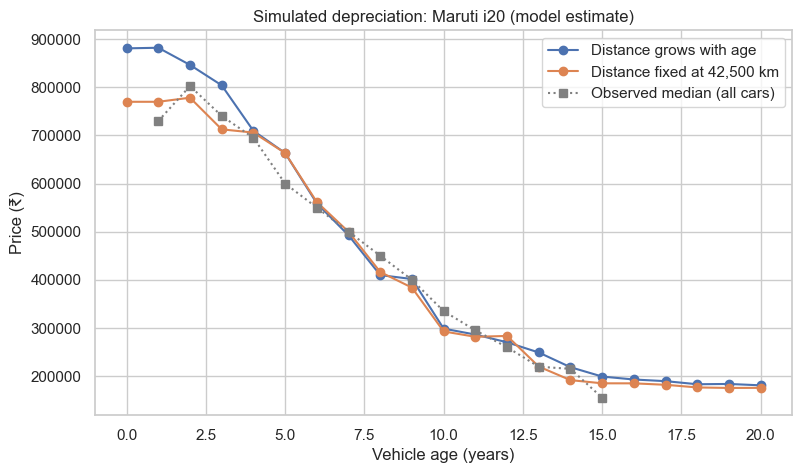

In [48]:
ref = {c: df[c].mode()[0] for c in CAT}
ref.update({c: df.loc[(df["brand"] == ref["brand"]) & (df["model"] == ref["model"]), c].median() for c in NUM if c not in ("vehicle_age", "km_driven", "km_per_year")})
kpy = float(df["km_per_year"].median())
ages = np.arange(0, 21)

def simulate(km_values):
    d = pd.DataFrame([{**ref, "vehicle_age": a, "km_driven": k} for a, k in zip(ages, km_values)])
    d["km_per_year"] = d["km_driven"] / d["vehicle_age"].clip(lower=1)
    return best_pipe.predict(d[FEATURES])

sim = pd.DataFrame({"age": ages, "Distance grows with age": simulate(ages * kpy), f"Distance fixed at {int(5 * kpy):,} km": simulate(np.full(len(ages), 5 * kpy))})
plt.figure(figsize=(9, 5))
for col in sim.columns[1:]:
    plt.plot(sim["age"], sim[col], marker="o", label=col)
plt.plot(age_t["vehicle_age"], age_t["median"], linestyle=":", color="gray", marker="s", label="Observed median (all cars)")
plt.title(f"Simulated depreciation: {ref['brand']} {ref['model']} (model estimate)")
plt.xlabel("Vehicle age (years)"); plt.ylabel("Price (₹)"); plt.legend(); plt.show()

In [49]:
s0 = sim.iloc[:, 1].values
print(f"Model estimate for this car: keeps {s0[5]/s0[0]:.0%} of its age-0 value after 5 years and {s0[10]/s0[0]:.0%} after 10 years.")
pd.DataFrame({"age": ages[1:], "yearly_drop_%": (1 - s0[1:] / s0[:-1]) * 100}).round(1).T

Model estimate for this car: keeps 75% of its age-0 value after 5 years and 34% after 10 years.


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
age,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
yearly_drop_%,-0.1,4.0,5.0,11.8,6.5,15.8,11.9,16.8,2.0,25.7,4.1,5.6,7.9,12.3,8.9,3.1,1.8,3.4,-0.3,1.6


##### 13. Saving the Model Bundle for the Streamlit App

In [50]:
opts = {c: sorted(df[c].dropna().unique().tolist()) for c in CAT if c != "model"}
opts["models_by_brand"] = df.groupby("brand")["model"].agg(lambda s: s.value_counts().index.tolist()).to_dict()
bundle = {
    "pipeline": best_pipe, "best_model": BEST, "features": FEATURES, "num": NUM, "cat": CAT, "options": opts,
    "median_kpy": kpy, "results": results,
    "best_params": {n: {k.split("__")[-1]: v for k, v in sr.best_params_.items()} for n, sr in [("Ridge", ridge_search), ("Random Forest", rf_search), ("HistGradientBoosting", hgb_search)]},
    "eda_sample": df.sample(min(15_000, len(df)), random_state=RANDOM_STATE).reset_index(drop=True),
    "importance": imp, "test_sample": pd.DataFrame({"actual": y_test.values, "predicted": best_pred}),
    "info": {"file_mb": file_mb, "raw_shape": raw_df.shape, "columns": list(raw_df.columns), "duplicates_removed": n_dups,
             "rows_clean": len(df), "train_rows": len(X_train), "test_rows": len(X_test), "price_range": (float(lo), float(hi)),
             "missing_pct_raw": (raw_df.isna().mean() * 100).round(2).to_dict()},
}
joblib.dump(bundle, "fairvalue_bundle.joblib", compress=3)
print("Saved fairvalue_bundle.joblib. Now run:  streamlit run app.py")

Saved fairvalue_bundle.joblib. Now run:  streamlit run app.py


##### 14. Conclusion
- Three regression models were tuned and compared on a random 80:20 split using MAE, RMSE and R². The best (lowest MAE) is saved with its full preprocessing pipeline.
- Depreciation curves from the simulator are **model estimates**; the observed curve mixes different cars and is not one car's price history.
- Prices are listing (asking) prices in ₹ from one website, and `mileage` in this dataset means fuel efficiency (kmpl), not distance driven (`km_driven`).